In [3]:
#importing libraries

import seaborn as sns
sns.set(style='darkgrid')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')


In [4]:
data=sns.load_dataset('titanic')
data

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


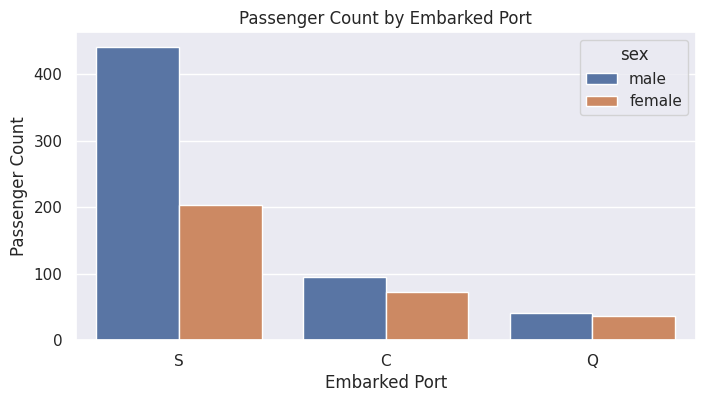

In [13]:
#1.Countplot
plt.figure(figsize=(8,4))
sns.countplot(x='embarked',data=data,hue='sex')
plt.title('Passenger Count by Embarked Port')
plt.xlabel('Embarked Port')
plt.ylabel('Passenger Count')
plt.show()



```markdown
### Insights: Passenger Count by Embarked Port
* **Dominant Port:** Southampton (S) was by far the most popular boarding port for both male and female passengers.
* **Gender Ratio:** Across all three boarding locations (Southampton, Cherbourg, and Queenstown), more male passengers boarded than female passengers, with the difference being most pronounced at Southampton.
```

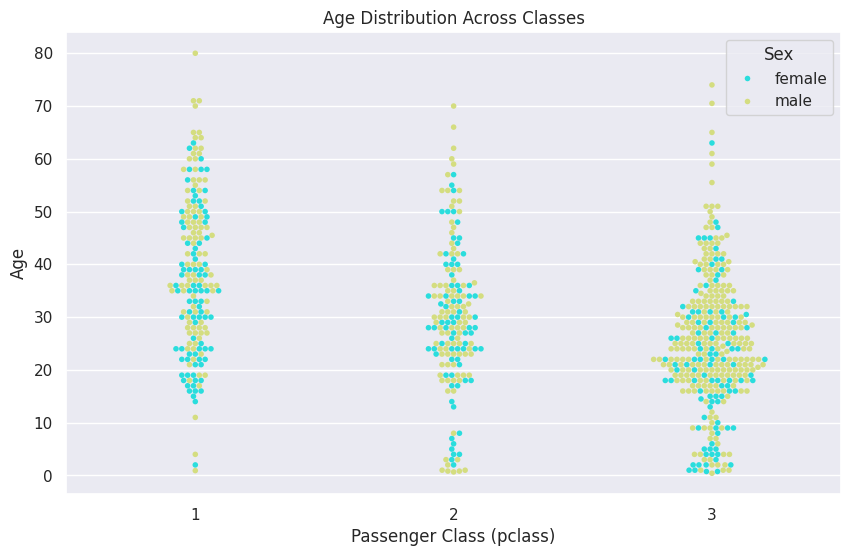

In [8]:
# 2.Swarmplot
plt.figure(figsize=(10, 6))
sns.swarmplot(x='pclass', y='age',data=data, hue='sex', palette='rainbow', size=4)
plt.title('Age Distribution Across Classes')
plt.xlabel('Passenger Class (pclass)')
plt.ylabel('Age')
plt.legend(title='Sex')
plt.show()

```markdown
### Insights: Age Distribution Across Classes
* **Age & Class Relationship:** First-class passengers skew older, with a concentration of passengers in their 30s, 40s, and 50s. Third-class passengers skew significantly younger, heavily concentrated between ages 15 and 35.
* **Children:** Children (passengers under 10 years old) are visible across all classes, but a larger absolute number of young children traveled in third class.
```

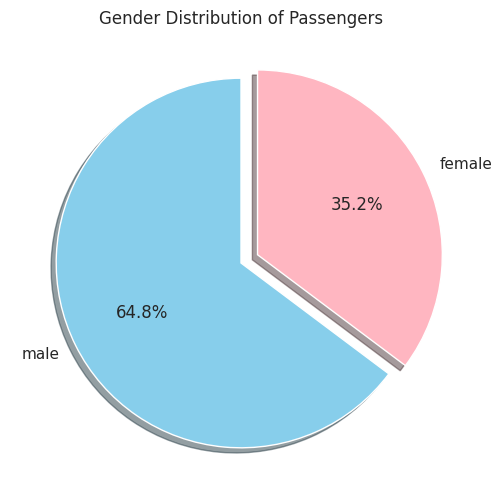

In [14]:
#3.Piechart
gender_counts = data['sex'].value_counts()


explode = (0, 0.1)

plt.figure(figsize=(6, 6))
plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['skyblue', 'lightpink'],
    explode=explode,
    shadow=True
)
plt.title('Gender Distribution of Passengers')
plt.show()

```markdown
### Insights: Gender Distribution of Passengers
* **Gender Split:** Almost two-thirds of the passengers onboard were male (64.8%), while female passengers accounted for just over one-third (35.2%). This baseline distribution is key when interpreting class and survival demographics.
```

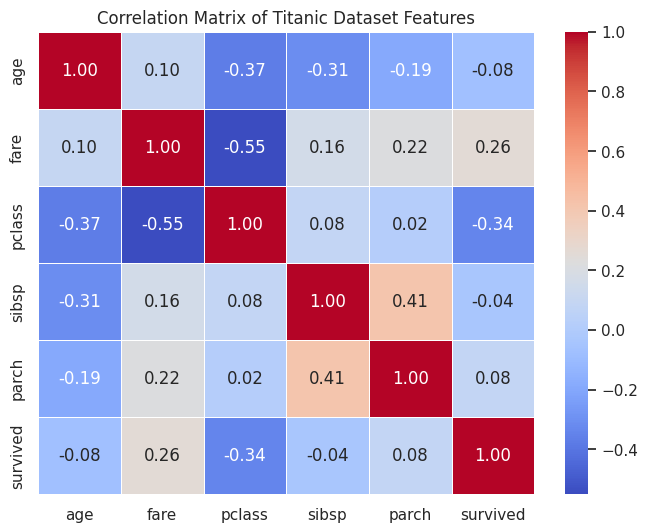

In [10]:
# 4. Heatmap: Correlation Matrix
selected_cols = ['age', 'fare', 'pclass', 'sibsp', 'parch', 'survived']
correlation_matrix = data[selected_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Titanic Dataset Features')
plt.show()

```markdown
### Insights: Correlation Matrix of Features
* **Fare vs Class:** There is a strong negative correlation (-0.55) between `fare` and `pclass`, confirming that lower class numbers (1st class) paid significantly higher fares.
* **Survival vs Class & Fare:** Survival is negatively correlated with passenger class (-0.34) and positively correlated with fare (0.26), indicating that higher-class passengers (who paid more) had better survival rates.
* **Family Size:** A strong positive correlation (0.41) exists between `sibsp` (siblings/spouses) and `parch` (parents/children), showing that families tended to travel together.
```

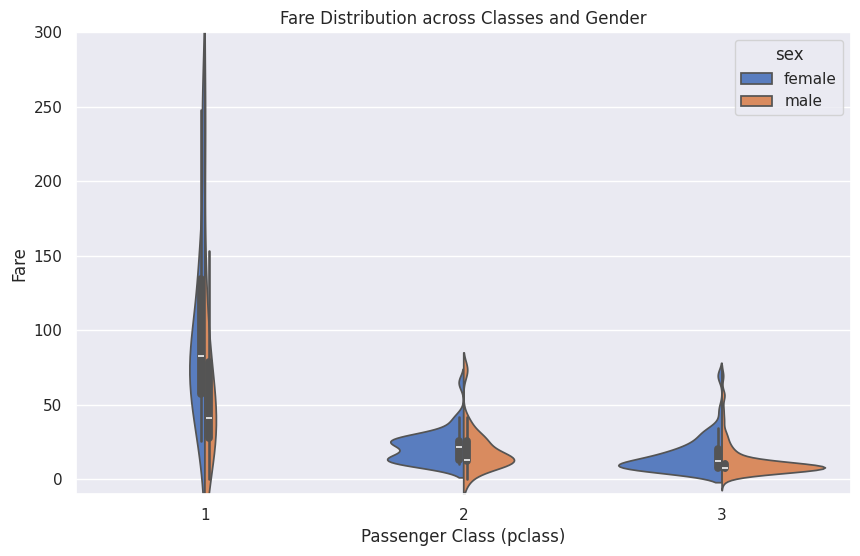

In [11]:
# 5. Violin Plot: Fare by Class and Gender
plt.figure(figsize=(10, 6))
# We use pclass or class as the x-axis, fare as the y-axis, and sex to separate
sns.violinplot(data=data, x='pclass', y='fare', hue='sex', split=True, palette='muted')
plt.title('Fare Distribution across Classes and Gender')
plt.xlabel('Passenger Class (pclass)')
plt.ylabel('Fare')
# Limiting y-axis if there are extreme outliers in fare for better visualization clarity
plt.ylim(-10, 300)
plt.show()

```markdown
### Insights: Fare Distribution across Classes and Gender
* **High-End Outliers:** First-class fares show a very wide, long-tailed distribution reaching up to $300 (and beyond), with females generally paying higher median fares within first class.
* **Lower Classes:** Second and third-class fares are extremely clustered near the bottom (under $50), highlighting the massive economic disparity between first-class passengers and the rest of the ship.
```

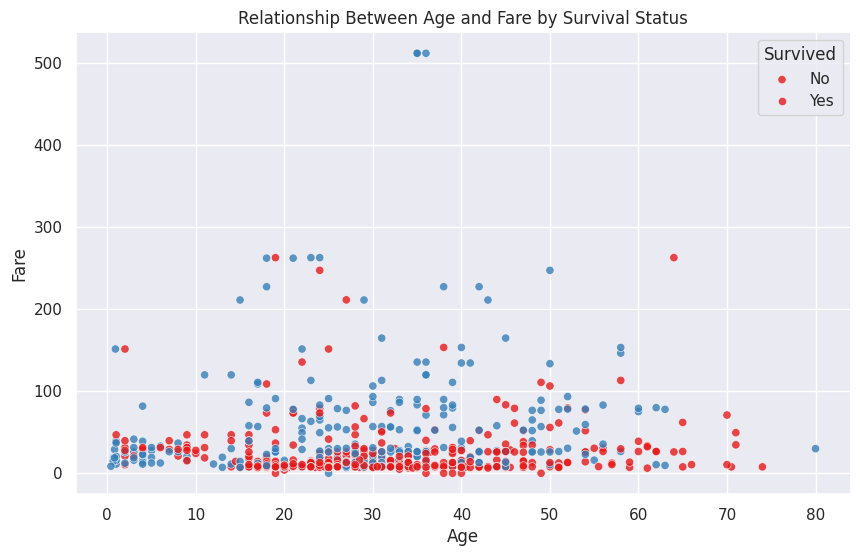

In [12]:
# 6. Scatter Plot: Age vs Fare
plt.figure(figsize=(10, 6))
sns.scatterplot(data=data, x='age', y='fare', hue='survived', palette='Set1', alpha=0.8)
plt.title('Relationship Between Age and Fare by Survival Status')
plt.xlabel('Age')
plt.ylabel('Fare')
plt.legend(title='Survived', labels=['No', 'Yes'])
plt.show()

```markdown
### Insights: Relationship Between Age and Fare by Survival Status
* **Survival Density:** Passengers who paid higher fares (located higher up on the y-axis) have a much higher density of survival (colored blue).
* **Demographics:** The majority of casualties (colored red) are clustered at lower fare rates ($50 or less) across almost all age brackets, while younger children (left side of the x-axis) show a strong survival rate regardless of fare.
```